In [ ]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

In [ ]:
def plot_learning_curve(history):
    # Graficar exactitud
    plt.figure()
    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.title('accuracy Curves')
    plt.legend()
    plt.show()

    # Graficar pérdida
    plt.figure()
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss Curves')
    plt.legend()
    plt.show()


In [ ]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        logical_gpus = tf.config.list_logical_devices('GPU')
        print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
    except RuntimeError as e:
        print(e)

1 Physical GPUs, 1 Logical GPUs


In [ ]:
(X_train, y_train), (X_test_full, y_test_full) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
X_test, X_val, y_test, y_val= train_test_split(
    X_test_full, y_test_full, test_size=0.50, random_state=42
)

In [ ]:
X_train.shape, X_test.shape, X_val.shape

((60000, 28, 28), (5000, 28, 28), (5000, 28, 28))

In [ ]:
for row in X_train[0]:
  print(" ".join(f"{val:3}" for val in row))

  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136 175  26 166 255 247 127   0   0   0   0
  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253 225 172 253 242 195  64   0   0   0   0
  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251  93  82  82  56  39   0   0   0   0   0
  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 182 247 241   0   0   0   0   0   0   0   0 

In [ ]:
X_train = X_train / 255.0
X_val = X_val / 255.0
X_test = X_test / 255.0

In [ ]:
X_train[0].shape

(28, 28)

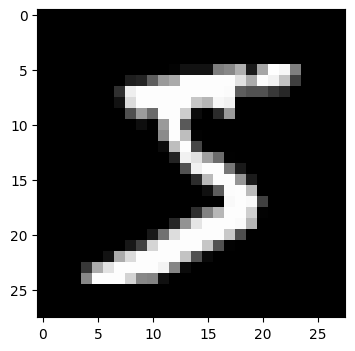

In [ ]:
plt.figure(figsize=(4,4))
plt.imshow(X_train[0], cmap="gray", vmin = 0, vmax=1.0)
plt.show()

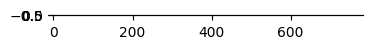

In [ ]:
plt.figure(figsize=(4,4))
plt.imshow(X_train[0].ravel().reshape(1, 784),  cmap="gray", vmin = 0, vmax=1.0)
plt.show()

In [ ]:
(X_train.shape[1],)

(28,)

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 128, activation = "relu"),
    tf.keras.layers.Dense(units = 64, activation = "relu"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])


model.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs = 20,
    batch_size = 32,
    validation_data = (X_val, y_val)
)

Epoch 1/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 3ms/step - accuracy: 0.9314 - loss: 0.2361 - val_accuracy: 0.9592 - val_loss: 0.1341
Epoch 2/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9699 - loss: 0.0991 - val_accuracy: 0.9702 - val_loss: 0.0989
Epoch 3/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9777 - loss: 0.0699 - val_accuracy: 0.9716 - val_loss: 0.0935
Epoch 4/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9828 - loss: 0.0532 - val_accuracy: 0.9712 - val_loss: 0.0977
Epoch 5/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9870 - loss: 0.0403 - val_accuracy: 0.9722 - val_loss: 0.1013
Epoch 6/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9884 - loss: 0.0354 - val_accuracy: 0.9754 - val_loss: 0.0894
Epoch 7/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9907 - loss: 0.0283 - val_accuracy: 0.9768 - val_loss: 0.0898
Epoch 8/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9924 - loss: 0.0229 -

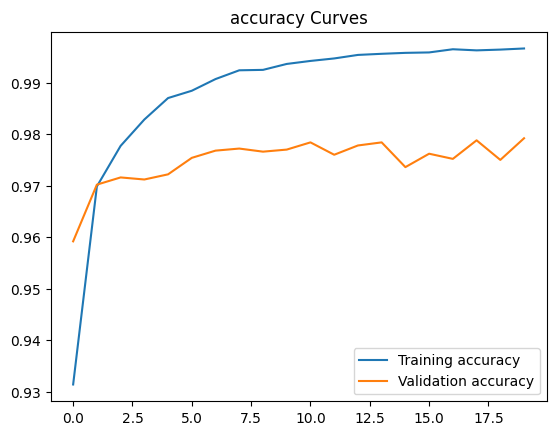

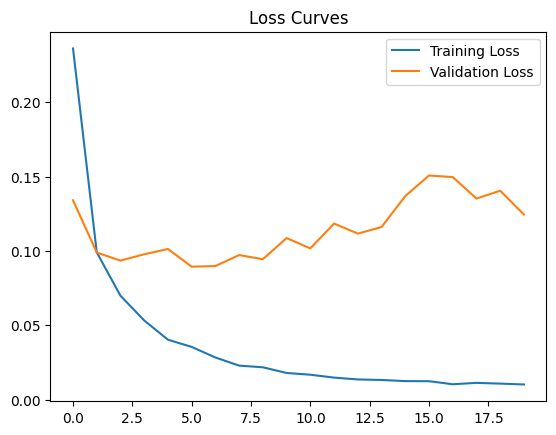

In [ ]:
plot_learning_curve(history)

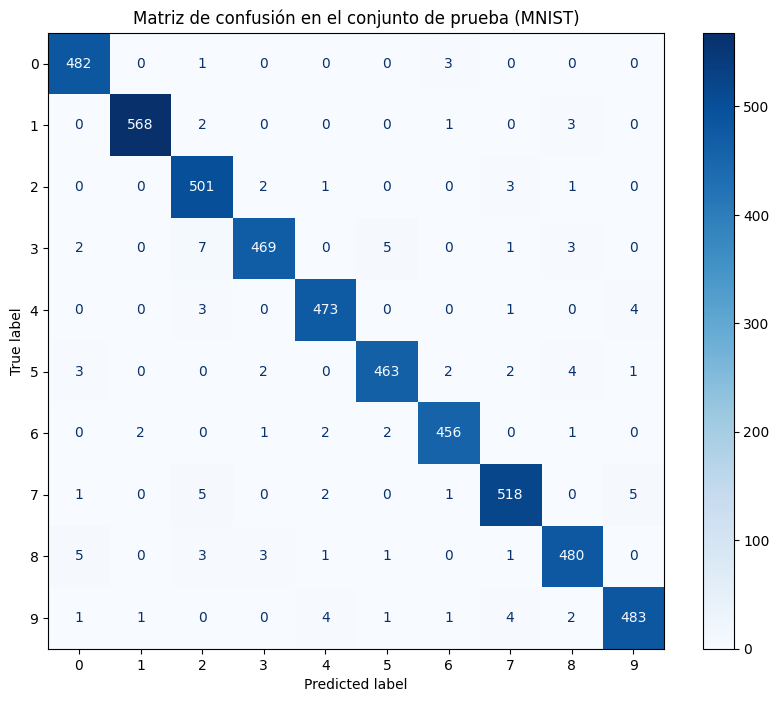

In [ ]:

# Obtener las probabilidades predichas para el conjunto de prueba
probabilidades = model.predict(X_test, verbose=0)

# Para multiclase, tomamos el índice con la probabilidad más alta
y_pred = np.argmax(probabilidades, axis=1)

# Graficar la matriz de confusión
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=[str(i) for i in range(10)],
    cmap="Blues",
    ax=ax,
)
plt.title("Matriz de confusión en el conjunto de prueba (MNIST)")
plt.grid(False)
plt.show()

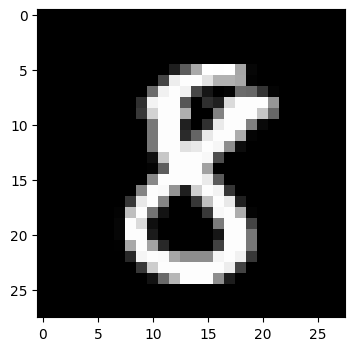

In [ ]:
# Predicción
plt.figure(figsize=(4,4))
plt.imshow(X_test[0], cmap="gray", vmin = 0, vmax=1.0)
plt.show()

In [ ]:
X_test[0].shape, X_test[0].reshape(1, 28, 28).shape

((28, 28), (1, 28, 28))

In [ ]:
# Predicción
np.argmax(model.predict(X_test[0].reshape(1, 28, 28)))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step


np.int64(8)

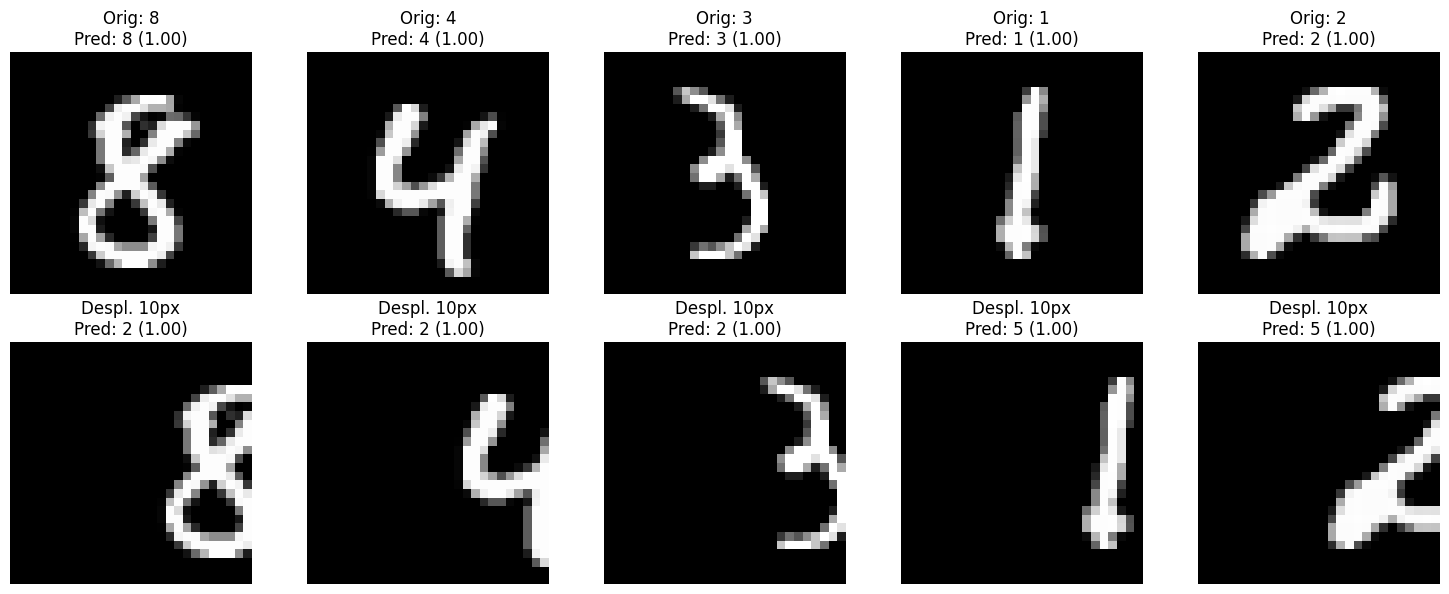

In [ ]:
# Seleccionar 5 imágenes de prueba
num_images = 5
original_images = X_test[:num_images]
original_labels = y_test[:num_images]

# Desplazar las imágenes 10 píxeles a la derecha
shifted_images = np.zeros_like(original_images)
for i in range(num_images):
    # Desplazamos a la derecha introduciendo ceros a la izquierda
    shifted_images[i, :, 10:] = original_images[i, :, :-10]

# Realizar predicciones para originales y desplazadas
preds_original = model.predict(original_images, verbose=0)
preds_shifted = model.predict(shifted_images, verbose=0)

# Graficar los resultados de la comparación
fig, axes = plt.subplots(2, num_images, figsize=(15, 6))

for i in range(num_images):
    # Mostrar imagen original
    axes[0, i].imshow(original_images[i], cmap='gray')
    pred_orig_label = np.argmax(preds_original[i])
    pred_orig_conf = preds_original[i][pred_orig_label]
    axes[0, i].set_title(f"Orig: {original_labels[i]}\nPred: {pred_orig_label} ({pred_orig_conf:.2f})")
    axes[0, i].axis('off')

    # Mostrar imagen desplazada
    axes[1, i].imshow(shifted_images[i], cmap='gray')
    pred_shift_label = np.argmax(preds_shifted[i])
    pred_shift_conf = preds_shifted[i][pred_shift_label]
    axes[1, i].set_title(f"Despl. 10px\nPred: {pred_shift_label} ({pred_shift_conf:.2f})")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

# Modelo 2

In [ ]:
model2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 128, activation = "relu"),
    tf.keras.layers.Dense(units = 2, activation = "linear", name = "rep_2d"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])


model2.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
model2.fit(
    X_train,
    y_train,
    epochs = 10,
    batch_size = 32,
    validation_data = (X_val, y_val)
)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.7498 - loss: 0.7973 - val_accuracy: 0.8898 - val_loss: 0.5036
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9061 - loss: 0.4185 - val_accuracy: 0.9166 - val_loss: 0.3870
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9288 - loss: 0.3085 - val_accuracy: 0.9322 - val_loss: 0.3163
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9408 - loss: 0.2462 - val_accuracy: 0.9330 - val_loss: 0.2996
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9488 - loss: 0.2081 - val_accuracy: 0.9382 - val_loss: 0.2757
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9561 - loss: 0.1758 - val_accuracy: 0.9390 - val_loss: 0.2807
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9603 - loss: 0.1544 - val_accuracy: 0.9440 - val_loss: 0.2770
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9657 - loss: 0.1323 - 

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


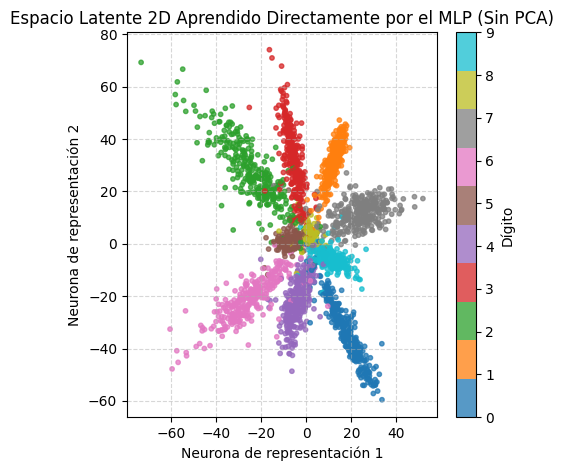

In [ ]:
extractor = tf.keras.Model(
    inputs = model2.inputs,
    outputs = model2.get_layer("rep_2d").output
)

n = 3000
x_visual = X_val[:n]
y_visual = y_val[:n]

puntos2d = extractor.predict(x_visual)

plt.figure(figsize=(5,5))
scatter_plot = plt.scatter(
    puntos2d[:, 0],
    puntos2d[:, 1],
    c=y_visual,
    cmap="tab10",
    s=10,
    alpha=0.75,
)
plt.title("Espacio Latente 2D Aprendido Directamente por el MLP (Sin PCA)")
plt.xlabel("Neurona de representación 1")
plt.ylabel("Neurona de representación 2")
plt.colorbar(scatter_plot, ticks=range(10), label="Dígito")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()